# Offshore Shell-Company Triage in the Panama Papers with Cypher and `sem_decide`

A compliance team faces 213,634 offshore companies that look nearly identical on paper. The highest-priority cases belong to **nominee clusters** -- hub officers controlling 10 or more companies -- a structural pattern invisible in any single company record.

This notebook runs one Cypher query over the ICIJ Panama Papers ownership graph to isolate companies linked to hub officers, then invokes `CALL graphistry.sem_decide($sem)` to score their profiles with typed, probability-calibrated decisions. Five benchmark stages measure what graph filtering, packed decisions, deduplication, caching, and `min_p` abstention save.

**Background:** [GFQL Semantic Operators Reference](../../gfql/builtin_calls.html#gfql-semantic-table-operators) | [Interactive Tour](gfql_semantic_operators.html)

![Five stages: time, cost, and precision](gfql_semantic_fraud_aml_chart.png)

*Generated from the run below using the default calibrated simulator ($0, no API key). Set `DEMO_LIVE=1` to measure a live model.*

| Section | What you get |
|---|---|
| **The pipeline in one Cypher query** | Hub-officer traversal, `CALL graphistry.sem_decide($sem)`, cost plan, and trace |
| **Simulated default vs. live mode** | What is real, what is simulated, and how name-blind screening works |
| **Data, graph schema, and typed questions** | ICIJ archive, company profiles, hub definition, and the three questions |
| **Stages 1-5** | Side-by-side tables comparing naive scan, flat filter, GFQL, dedupe/cache, and `min_p` |
| **Benchmark chart and cluster graph** | Three-panel log chart plus officer-cluster subgraph extraction |
| **Run against a live model** | Opt-in live configuration, budget caps, and environment variables |

**Prerequisites & data.** The first run downloads the public ICIJ Offshore Leaks archive (72 MB) into `/tmp/icij-offshore-cache`. Start Jupyter in `demos/gfql/` (or add it to `sys.path`) so Python finds `fraud_aml_helpers.py`. Set `DEMO_LIVE=1` to run against a live provider.

*Data attribution: [ICIJ Offshore Leaks Database](https://offshoreleaks.icij.org/pages/database) (Panama Papers), licensed under [ODbL 1.0](https://opendatacommons.org/licenses/odbl/1-0/) and [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/). Appearing in the archive is not evidence of wrongdoing.*

In [1]:
import polars as pl

import fraud_aml_helpers as h

h.init()    # download (once), build the profiles, the labels and the graph

from graphistry import e_forward, n
from graphistry.compute.semantic import (
    MemorySemanticCache,
    bind_providers,
    explain_sem_decide,
    semantic_summary,
    semantic_trace,
    semantic_verdicts,
)
from fraud_aml_helpers import (
    EVIDENCE,
    OPTIONS,
    PARALLEL,
    QUESTIONS,
    decisions_provider,
    g,
    session_for,
    show,
)

print("mode:", "LIVE model (opt in)" if h.DEMO_LIVE else "simulated model ($0, no key)")

ICIJ Offshore Leaks, Panama Papers (full download) | 213,634 companies | 238,402 officers | 14,110 agents | 522,997 edges | read in 6 s


213,634 companies | 1,155 hub officers | 466,146 nodes | 522,997 edges
mode: simulated model ($0, no key)


## The pipeline in one Cypher query

One `g.gfql(...)` call combines nominee-cluster detection with name-blind profile screening:

- **Input & query:** `MATCH` walks from hub officers (`hub: true`) across `officer_of` edges to their `entity` nodes, then `WITH DISTINCT` projects five profile fields into `CALL graphistry.sem_decide($sem)`.
- **Config (`$sem`):** Passes three typed questions, evidence columns, the bound provider alias (`"triage"`), concurrency, and `min_p=0.85` as a single parameter payload.
- **Output:** Returns one row per cluster company with typed verdicts, probabilities, a dry-run cost plan (`explain_sem_decide`), and an execution trace (`semantic_trace`).

*Cypher notes:* Labels `(o:officer)` and `[:officer_of]` match the `type` column on nodes and edges and execute natively on `engine="polars"`. Deduplication (`dedupe=True`) is enabled here by default, cutting 23,964 companies to 15,749 unique calls; Stages 1-3 below set `dedupe=False` to compare row-for-row against a plain loop.

In [2]:
# 1. Config: typed questions, evidence columns and guardrails travel as ONE $param
provider = decisions_provider(session_for())  # simulated unless DEMO_LIVE=1
sem = dict(
    questions=QUESTIONS,
    evidence=EVIDENCE,
    provider="triage",
    task_id="offshore-triage",
    id_col="entity_id",
    max_concurrency=PARALLEL,
    require_probabilities=True,
    min_p=0.85,
    **OPTIONS,  # live mode adds budget={"max_cost_usd": 0.50}
)

# 2. Run: ONE query narrows the graph, then asks the model about the rows that remain
cache = MemorySemanticCache()
with bind_providers({"triage": provider}, cache=cache), semantic_trace() as runs:
    triaged = g.gfql(
        """
        MATCH (o:officer {hub: true})-[:officer_of]->(c:entity)
        WITH DISTINCT c.id AS entity_id,
                      c.jurisdiction AS jurisdiction,
                      c.status AS status,
                      c.incorporated AS incorporated,
                      c.intermediary AS intermediary,
                      c.officers AS officers
        CALL graphistry.sem_decide($sem)
        """,
        params={"sem": sem},
        engine="polars",
    )

# 3. Output: the plan for the same rows (no request), status counts, verdicts, the trace
rows = triaged._nodes.to_pandas()
plan = h.plan_of(rows, provider, sem)
verdict = semantic_verdicts(rows, "aml_priority", positive="escalate")
show(semantic_summary(rows))
show(verdict.value_counts().rename("companies").to_frame().T)
print(
    f"plan: {plan['planned_calls']:,} calls for {plan['active_rows']:,} companies, "
    f"dedupe saves {plan['dedupe_saved_rows']:,} | "
    f"run: {runs[0]['provider_calls']:,} calls, billed ${runs[0]['billed_cost_usd']:.2f}"
)


*SIMULATED model on real ICIJ Panama Papers data*

,ok,uncertain,error,skipped,unanswered,unanswered_pct
question,,,,,,
nominee_or_shell_risk,17279,6685,0,0,6685,27.90
entity_role,16985,6979,0,0,6979,29.12
aml_priority,17041,6923,0,0,6923,28.89


*SIMULATED model on real ICIJ Panama Papers data*

,no,uncertain,yes,error,skipped
companies,14677,6923,2364,0,0


plan: 15,749 calls for 23,964 companies, dedupe saves 8,215 | run: 15,749 calls, billed $14.08


In [3]:
# The same query as a GFQL chain (Python objects), on the Polars engine
cluster_chain = [
    n({"type": "officer", "hub": True}),
    e_forward({"type": "officer_of"}),
    n({"type": "entity"}, name="member"),
]
chain_ids = g.gfql(cluster_chain, engine="polars")._nodes.filter(pl.col("member"))["id"]
hero_ids = set(triaged._nodes["entity_id"])
assert set(chain_ids) == hero_ids, "Cypher and the chain must agree"
print(f"{len(chain_ids):,} companies from the chain: the same rows as the Cypher query")

23,964 companies from the chain: the same rows as the Cypher query


A `yes` verdict means the model predicted `escalate` with probability `>= 0.85`. Rows below `0.85` become `uncertain` and route to a compliance review queue. Any `error` or `skipped` row fails closed and is never counted as `no`.

## Simulated default vs. live mode

- **Real:** All 213,634 Panama Papers companies, 238,402 officers, 14,110 intermediaries, 522,997 edges, and every Cypher/GFQL query.
- **Simulated by default:** No API key is needed and no network request is sent to an LLM ($0). A calibrated mock provider replays fixed draws per distinct profile so every stage sees identical model behavior while only the pipeline changes.
- **Rule-based labels & name-blind prompts:** The ICIJ archive contains no illegality labels; held-out scores come from a fixed screening rulebook combined with the officer graph (not adjudicated AML ground truth). Prompts omit company names to model name-blind screening, and output tables mask private individuals as `<person>`. Set `DEMO_LIVE=1` at the end to measure a real model.

## Data, graph schema, and typed questions

### ICIJ dataset, profiles, and nominee hubs
- **Archive:** Downloads the ICIJ Offshore Leaks zip to `/tmp/icij-offshore-cache` (verifying SHA-256 against the snapshot used for committed outputs) and loads Panama Papers rows from `nodes-entities.csv`, `nodes-officers.csv`, `nodes-intermediaries.csv`, and `relationships.csv`.
- **Name-blind profiles:** Each company profile contains `jurisdiction`, `status`, incorporation year, `intermediary`, and the first two sorted `officers` (`none listed` if absent). Omitting the company name exposes identical boilerplate shell structures across companies -- ideal input for `dedupe=True`.
- **Graph schema & hubs:** Nodes have `type` in `{entity, officer, agent}`; edges have `type` in `{officer_of, intermediary_of}`. A **hub** is an officer linked to `>= 10` companies, excluding bearer placeholders (`THE BEARER` appears on 70,948 companies as a share-type marker rather than a single actor).
- **Name masking:** Output tables show hub officers, large agents (`>= 100` companies), and bearer placeholders, replacing other individuals with `<person>`.

### Typed questions and rulebook labels
For each company profile, the model answers three typed questions:

| Question | Kind | Values |
|---|---|---|
| `nominee_or_shell_risk` | `predicate` | `True` / `False` (profile resembles a nominee or shell vehicle) |
| `entity_role` | `choice` | `holding_shell`, `trust_or_foundation`, `operating_company`, `nominee_vehicle` |
| `aml_priority` | `score` | `low`, `review`, `escalate` |

Held-out screening rulebook (stand-in for a compliance list):
- **Risk trigger:** Officer name contains `nominee`, `subscribers`, `secretaries`, `bearer`, or `portador`, or company status is a shelf/trash company.
- `entity_role`: `trust_or_foundation` (trust/foundation/stiftung/anstalt/fideicomiso officer) -> `nominee_vehicle` (nominee/bearer officer) -> `holding_shell` (shelf/defaulted/dissolved/inactive status) -> `operating_company`.
- `aml_priority`: `low` (no risk trigger), `escalate` (risk trigger in Niue, Samoa, Seychelles, or Anguilla -- an illustrative jurisdiction list), else `review`.

**Positive class:** A company scored `escalate` **and** connected to a hub officer. A single profile cannot reveal cluster membership; the ownership graph supplies it.

### Simulator assumptions
- **Calibrated confidence:** Draws `p` from `Beta(24, 1.5)` (mean 0.94) for `low` profiles and `Beta(10, 2)` (mean 0.83) for `review`/`escalate`, answering correctly with probability `p`.
- **Cost & latency:** Token counts come from real profile lengths (4 chars/token); prices and latencies are fixed modeling assumptions listed below.

In [4]:
h.data_summary()

,edges
rel_type,
officer_of,309363
intermediary_of,213634


213,634 companies | 1,155 hub officers | 23,964 companies have a hub officer


127,791 distinct profiles: 40% of the companies repeat the profile of another one


213,624 distinct profiles if the company name were part of the prompt: only 10 companies would repeat one, and `dedupe` would save almost nothing


,jurisdiction,status,incorporated,intermediary,officers
0,Samoa,Defaulted,2006,ORION HOUSE SERVICES (HK) LIMITED,<person>; MOSSFON SUBSCRIBERS LTD.
1,Samoa,Defaulted,2006,ORION HOUSE SERVICES (HK) LIMITED,MOSSFON SUBSCRIBERS LTD.; <person>
2,Samoa,Defaulted,2006,ORION HOUSE SERVICES (HK) LIMITED,MOSSFON SUBSCRIBERS LTD.; <person>


213,634 companies | 50,374 have risk text | 10,754 are escalate by the rules | 23,964 are in a nominee cluster | 4,258 are escalate in a cluster
columns that the model reads: ['jurisdiction', 'status', 'incorporated', 'intermediary', 'officers'] (no company name, no id, no hub, no label)


,companies,in_cluster
aml_priority,,
low,163260,11173
review,39620,8533
escalate,10754,4258


,nodes,edges
type,,
agent,14110.0,NaN
entity,213634.0,NaN
officer,238402.0,NaN
intermediary_of,NaN,213634.0
officer_of,NaN,309363.0


,assumption,value
0,model confidence p (mean),"low-risk profiles 0.94, the rest 0.83"
1,chat latency for one request,0.9 s
2,decisions latency for one request,1.2 s + 0.15 s for each question
3,"parallel requests, stages 1 to 3",1 (one request at a time)
4,"parallel requests, stages 4 and 5",8
5,price per million tokens (input / output),$2.5 / $10.0


## Stages 1-3: Naive scan, flat table filter, and GFQL cluster filter

All three stages ask the same three questions sequentially via the chat provider (`max_concurrency=1`, `dedupe=False`), matching a plain LLM loop.

1. **Stage 1 -- Naive scan:** Scores all 213,634 companies without graph context, flagging thousands of standalone entities that do not belong to a nominee cluster.
2. **Stage 2 -- Flat table filter (no graph):** Keeps companies with a nominee/bearer officer string, shelf status, or high-secrecy jurisdiction using the entity table alone. Retains all positives but keeps a large volume of non-cluster rows.
3. **Stage 3 -- GFQL cluster filter:** Runs the hero graph traversal in Polars (`officer {hub: true}` -> `officer_of` -> `entity`). Cuts candidate volume well below Stage 2 and removes non-cluster false flags before any LLM call, reducing spend and lifting precision.

In [5]:
h.stage1()
h.stage2()

rows asked: 213,634 of 213,634 | local run time 147.9 s


*SIMULATED model on real ICIJ Panama Papers data*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors
0,213634,213634,640902,263.374,576811.8,16741,3518,0,0.21,0.826,0


*SIMULATED model on real ICIJ Panama Papers data*

,companies flagged by the naive scan
"right: escalate by the rules, in a nominee cluster",3518
"escalate by the rules, but in no cluster",5561
model mistake: not escalate by the rules,7662


213,634 companies -> 72,525 after the flat filter (2.9x fewer rows)


*SIMULATED model on real ICIJ Panama Papers data*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors
0,72525,72525,217575,88.974,195817.5,12777,3518,0,0.275,0.826,0


In [6]:
h.stage3()

,step,companies left,removed by,positives kept
0,all companies,213634,,4258
1,flat filter,72525,plain table filter,4258
2,GFQL cluster filter,23964,"GFQL on polars, 101 ms (median of 5)",4258


GFQL: 213,634 -> 23,964 companies in 101 ms (traversal over the existing hub flag) | the flat filter keeps 72,525
check: a pandas count of the companies of each officer, from the edge table, gives the same companies (a different job, so its time is not shown)
The 4,258 positives sit under 101 hub officers, but 85% of them (3,613) sit under one hub officer (MOSSFON SUBSCRIBERS LTD.). Every quality number below is mostly about that one cluster. Positives are counted by construction from the same cluster evidence, so GFQL keeps all of them.
The flat filter keeps 72,525 rows and GFQL keeps 23,964. The flat filter keeps 6,496 companies that the rules call escalate but that sit in no cluster, and it drops 0 positives. GFQL keeps 9,688 cluster companies that the flat filter drops.


*SIMULATED model on real ICIJ Panama Papers data*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors
0,23964,23964,71892,30.423,64702.901,4487,3518,0,0.784,0.826,0


## Stages 4-5: Packed decisions, deduplication, caching, and `min_p`

4. **Stage 4 -- Packed decisions, concurrency, and `dedupe=True`:** `OpenAIDecisionsProvider` evaluates all three questions in one call with shared profile text, runs 8 calls concurrently (`max_concurrency=8`), and deduplicates identical name-blind profiles (copied answers bill `$0`). *Note:* deduplication saves ~34% of calls here because prompts omit the company name; including unique company names would leave almost no duplicates.
5. **Stage 5 -- `min_p` abstention, `sem_map` findings, and `MemorySemanticCache`:** `require_probabilities=True` and `min_p=0.85` route low-confidence rows to `uncertain`. `sem_map` then writes one compliance note per unique actionable profile enriched with its hub officer and cluster size (8 concurrent calls, deduplicated and capped by request count).

The diagnostic cells below report per-question accuracy, replay `min_p` thresholds over Stage 4 probabilities, and demonstrate `MemorySemanticCache`: because the cache stores pre-`min_p` answers, re-running with a stricter threshold serves 100% cache hits at `$0`.

In [7]:
h.stage4()
h.stage5()

probability kinds: {'native_decision': 23964}
dedupe: 8,215 of 23,964 companies share the profile of an earlier one and were not asked (34%)


*SIMULATED model on real ICIJ Panama Papers data*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors
0,23964,23964,15749,14.078,3248.332,4487,3518,0,0.784,0.826,0


*SIMULATED model on real ICIJ Panama Papers data*

,how the same rows are sent,requests,cost_usd,seconds
0,"chat, 1 question per call, 1 at a time (stage 3)",71892,30.423,64702.800
1,"chat, 1 question per call, 8 at once",71892,30.423,8087.850
2,"3 questions per call, 8 at once, dedupe=False",23964,21.380,4942.575
3,"3 questions per call, 8 at once, dedupe=True (stage 4)",15749,14.078,3248.231
4,"8 rows packed per call, 8 at once, dedupe=True",1969,18.201,1181.231


the aml_priority answers are the same with and without dedupe: True (true by construction of the simulator: the same profile gets the same draw)


escalate: 2364 | compliance queue: 6923 | findings: {'ok': 9287} | finding requests: 6,059 for 9,287 companies (dedupe) | sem_map cost $4.8312


*SIMULATED model on real ICIJ Panama Papers data*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors,uncertain_pct
0,23964,23964,21808,18.909,3929.969,2364,1898,2162,0.803,0.446,0,28.889


In [8]:
h.diagnostics()

*SIMULATED model on real ICIJ Panama Papers data*

,question,kind,stage 4 accuracy,stage 4 answered,stage 5 accuracy,stage 5 answered
0,nominee_or_shell_risk,predicate,0.884,23964,0.932,17279
1,entity_role,choice,0.874,23964,0.933,16985
2,aml_priority,score,0.880,23964,0.935,17041


*SIMULATED model on real ICIJ Panama Papers data*

,min_p,escalate,precision,recall,compliance queue
0,0.50,4463,0.785,0.823,1%
1,0.70,4016,0.794,0.749,7%
2,0.80,3084,0.791,0.573,19%
3,0.85,2364,0.803,0.446,29%
4,0.90,1460,0.823,0.282,45%
5,0.95,498,0.801,0.094,71%


*SIMULATED model on real ICIJ Panama Papers data*

,requests,cost_usd,modeled seconds,local seconds,answers from the cache
pass,,,,,
first pass (stage 4 settings),15749,14.078,3248.231,10.142,"0 of 23,964 rows"


*SIMULATED model on real ICIJ Panama Papers data*

,requests,cost_usd,modeled seconds,local seconds,answers from the cache
pass,,,,,
"second pass (min_p=0.85, new provider)",0,0.0,0.0,5.803,"23,964 of 23,964 rows"


cache: 47,247 entries, 30 MB | lookups 94,494 | hit rate 50% | puts 47,247
the second pass gives the same verdicts as stage 5, which asked the model: True


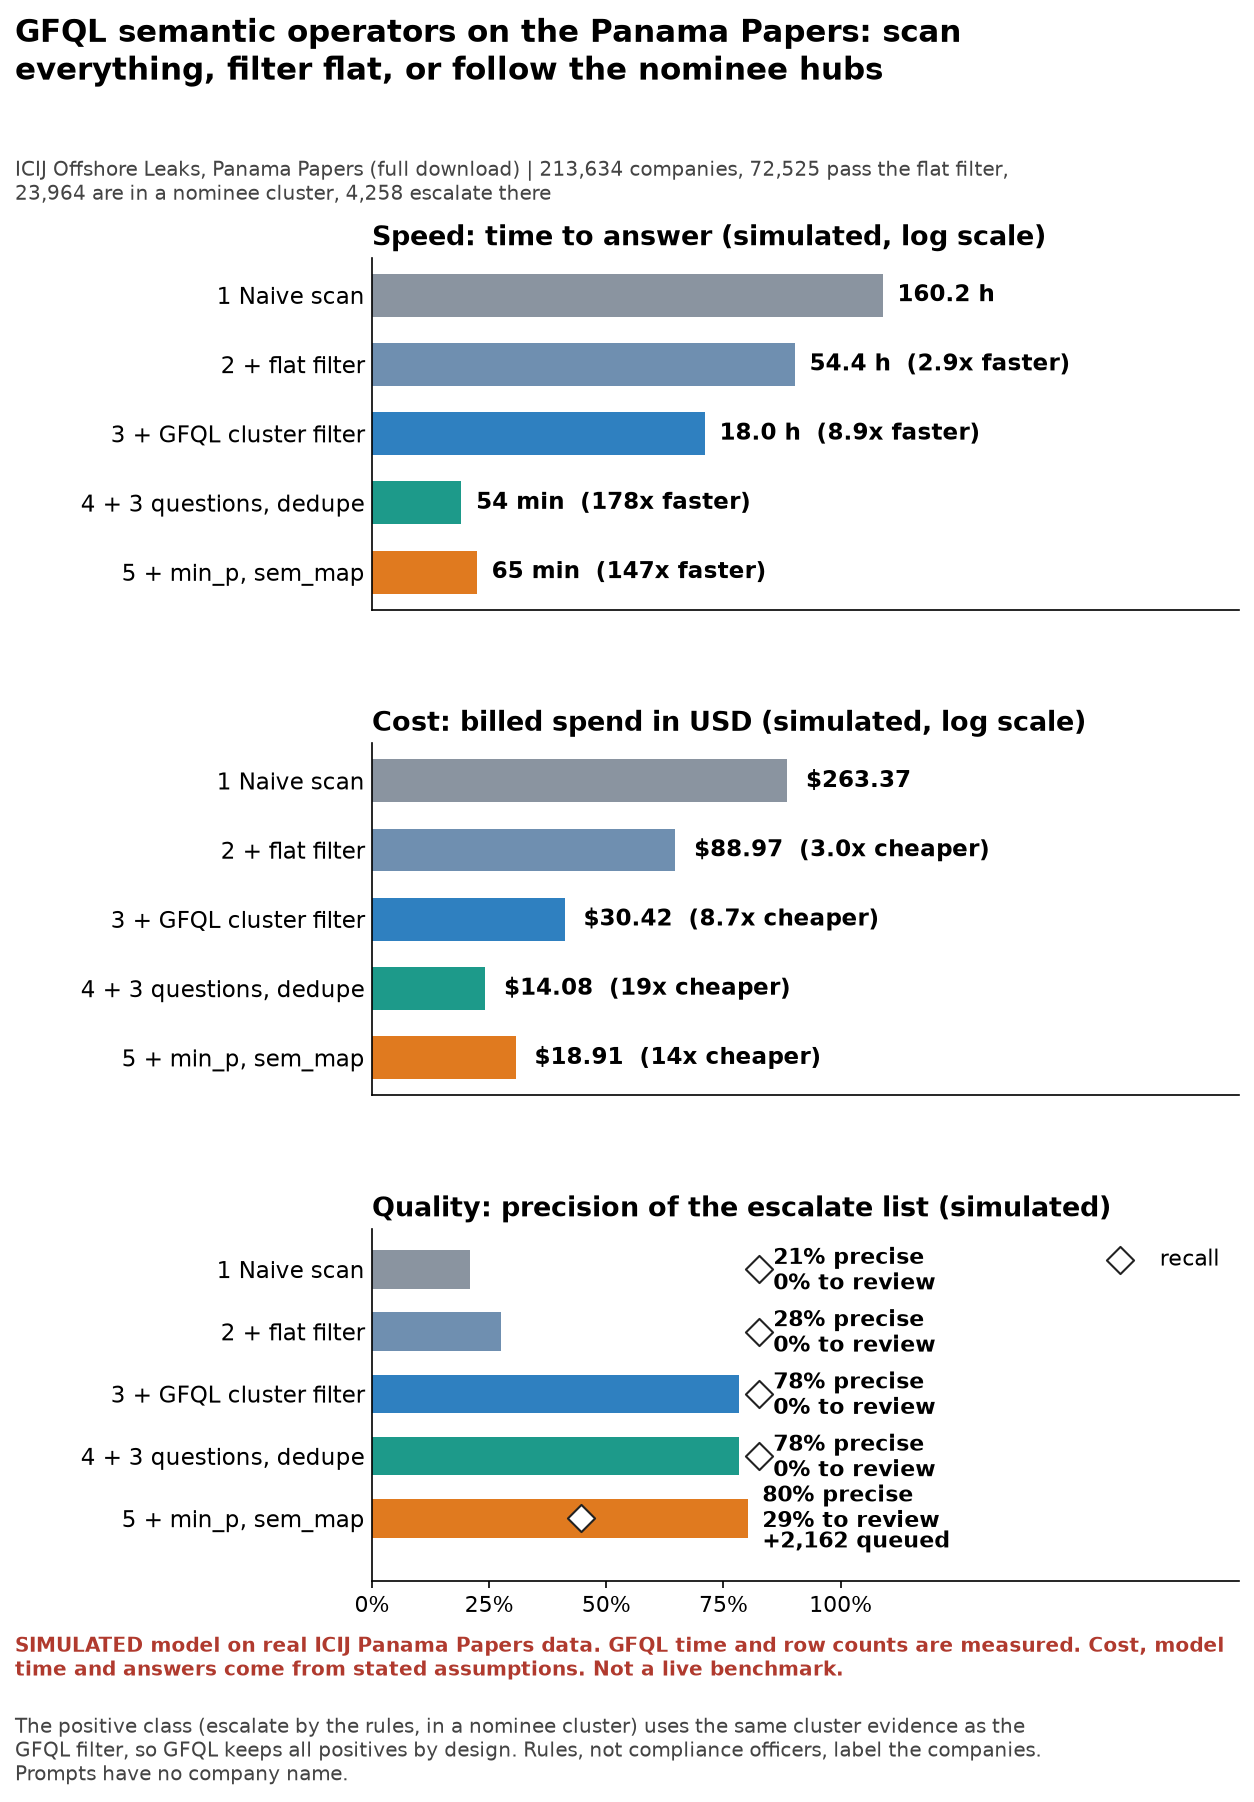

saved gfql_semantic_fraud_aml_chart.png


*SIMULATED model on real ICIJ Panama Papers data*

,companies read,cost vs the step before,time vs the step before
step,,,
1 Naive,213634,NaN,NaN
2 +flat filter,72525,2.960,2.946
3 +GFQL cluster filter,23964,2.925,3.026
"4 +3 questions, dedupe",23964,2.161,19.919
5 +min_p +sem_map,23964,0.745,0.827


In [9]:
h.chart()

## Reading the benchmark chart

The three panels above compare modeled runtime, spend (both log-scale), and `escalate` precision across all five stages. Stage 3 (GFQL cluster filtering) removes non-cluster companies to raise precision and cut rows, while Stage 4 (packed Decisions, 8-way concurrency, and `dedupe=True`) drives the bulk of the speed and cost reduction.

## The cluster graph

A reverse GFQL query starts at the `escalate` and `uncertain` companies and walks back along `officer_of` edges to expose their shared hub officers for visual investigation.

In [10]:
h.incident()

cluster query: 90 ms | 10189 nodes, 12512 edges
preview only: set DEMO_PLOT=1 after graphistry.register(...) to open the graph


,nodes
role,
flagged company,9287
hub officer,902


*SIMULATED model on real ICIJ Panama Papers data*

,hub_officer,flagged_companies,cluster_size
0,MOSSFON SUBSCRIBERS LTD.,3477,3882
1,CUSTODIAN LTD.,258,301
2,FIRST SHAREHOLDERS LIMITED,218,368
3,BROCK NOMINEES LIMITED,157,251
4,CONSTANT LTD.,137,316
5,ELCAN NOMINEES LIMITED,130,133
6,CAVERSHAM NOMINEES LIMITED,118,70
7,MOSTALINA INVESTMENTS S.A,108,118


*SIMULATED model on real ICIJ Panama Papers data*

,entity_id,hub_officer,hub_size,verdict,aml_priority__p,finding
0,10002699,MOSSFON SUBSCRIBERS LTD.,3882,flagged,0.995,"A Samoa company (Active), set up by ORION HOUSE SERVICES (HK) LIMI..."
1,10148177,FIRST SHAREHOLDERS LIMITED,368,uncertain,0.763,"A British Virgin Islands company (Shelf company), set up by MOSSAC..."
2,10106761,BOS NOMINEES (JERSEY) LIMITED,347,flagged,0.901,"A British Virgin Islands company (Active), set up by BOS TRUST COM..."
3,10153139,BOS SECRETARIES (JERSEY) LIMITED,332,flagged,0.930,"A British Virgin Islands company (Active), set up by BOS TRUST COM..."
4,10136689,CONSTANT LTD.,316,uncertain,0.838,"A British Virgin Islands company (Defaulted), set up by <person> w..."
5,10134289,CUSTODIAN LTD.,301,uncertain,0.843,"A British Virgin Islands company (Dissolved shelf company), set up..."


*SIMULATED model on real ICIJ Panama Papers data*

,jurisdiction,status,officers,aml_priority__p
16567,British Virgin Islands,Active,ATHNID LIMITED; TREX LIMITED,0.84997
1628,Samoa,Active,INDEPENDENT GUARDIAN TRUSTEES LTD; THE BEARER,0.84995
7934,British Virgin Islands,Active,Hanoverian Limited,0.84992
18102,British Virgin Islands,Active,Hanoverian Limited,0.84992
18282,British Virgin Islands,Active,Hanoverian Limited,0.84992


In [11]:
h.summary()

SIMULATED model on real ICIJ Panama Papers data | ICIJ Offshore Leaks, Panama Papers (full download)
Rows: 213,634 companies -> 72,525 after the flat filter -> 23,964 after the GFQL cluster filter (101 ms for the traversal over the existing hub flag).
The positives are concentrated: 85% of the 4,258 sit under one hub officer, so the quality numbers are mostly about one cluster.
GFQL keeps the companies in a nominee cluster, and all 4,258 escalate companies in one. That recall is by design: the positive class uses the same cluster evidence. The flat filter keeps 4,258 of them.
Cost and time fall at stage 3 because GFQL reads fewer companies than the flat filter ($88.97 and 54.4 h against $30.42 and 18.0 h). Stage 4 adds the shared call, concurrency and dedupe (34% of its companies repeat a profile, because the prompt has no company name; with the name, only 10 of all 213,634 companies would). Stage 5 adds findings and a queue, so it costs 34% more than stage 4.
Precision of the escalate

## Run against a live model (opt in)

Set `DEMO_LIVE=1` and restart the notebook to run against a live OpenAI-compatible provider. Live runs transmit profile text to your configured host and incur provider charges.

**Built-in guardrails:**
- Decision stages enforce `budget={"max_cost_usd": 0.50}` on estimated input cost (output tokens and retries are not capped; monitor your provider billing dashboard).
- Stages 1-3 evaluate a 50-company random sample and Stages 4-5 evaluate a 200-company sample, extrapolating cost and runtime to all rows (Stage 1 quality is omitted because 50 random rows contain almost no positives).
- `sem_map` findings are capped by request count, and the second cache pass is skipped to avoid extra spend.
- The chart footer switches to `"Measured with a live model"`.

Export these environment variables before starting Jupyter (never commit keys into a notebook):

| Variable | Purpose |
|---|---|
| `OPENAI_API_KEY` | API key for an OpenAI-compatible host |
| `OPENAI_BASE_URL` | Optional host URL for both chat and decisions (default `https://api.openai.com/v1`) |
| `OPENAI_CHAT_MODEL` | Chat model for Stages 1-3 and `sem_map` findings |
| `OPENAI_DECISIONS_MODEL` | Decisions model for Stages 4-5 |
| `PRICE_IN`, `PRICE_CACHED`, `PRICE_OUT` | Token prices in USD per 1M tokens |

*Data policy:* Although the ICIJ archive is public, it includes names of private individuals; live prompts send unmasked names and free-text `sem_map` findings may repeat them. Check your compliance policy before sending customer or KYC records to any external host.

## Appendix: Helper module

`fraud_aml_helpers.py` (located beside this notebook) implements ICIJ archive caching and parsing, profile construction, hub detection, the screening rulebook, the calibrated mock HTTP provider, stage runners, and chart rendering.

In [12]:
from IPython.display import Code

Code(filename="fraud_aml_helpers.py", language="python")

# flake8: noqa: F821
"""Helpers for the Panama Papers demo (gfql_semantic_fraud_aml.ipynb).

The notebook shows the GFQL and semantic-operator calls. This file holds the plumbing: the ICIJ download and parse, the company profiles,
the rulebook that labels them, the hub-officer computation, the simulated model (a calibrated mock HTTP session), the stage runner and the chart.
Call `init()` once, then `from fraud_aml_helpers import *`.
"""


import hashlib
import json
import math
import os
import re
import textwrap
import threading
import time
import warnings
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

import graphistry
from graphistry import e_forward, e_reverse, n
from graphistry.compute.predicates.is_in import is_in
from graphistry.compute.semantic import (CallableGenerationProvider, MemorySemanticCache, OpenAIChatProvider, OpenAIDecisionsProvider, ProviderCapabilities,
                                         TokenPrices, bind_providers, sem_decide, sem_map)
from IPython.display import Markdown, display

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

warnings.filterwarnings("ignore", message="Determining the column names of a LazyFrame")


DEMO_LIVE = os.environ.get("DEMO_LIVE") == "1"
ICIJ_URL = "https://offshoreleaks-data.icij.org/offshoreleaks/csv/full-oldb.LATEST.zip"
ICIJ_SHA256 = "9e5faeed998b5715157bbdb2a600681d1b5bda259ba004c998b3b2836d3c49aa"    # the archive that the committed outputs come from (generated 2026-09-09)
CACHE_DIR = Path("/tmp/icij-offshore-cache")
ARCHIVE = CACHE_DIR / "full-oldb.LATEST.zip"
SOURCE_NAME = "Panama Papers"
HUB_MIN = 10                                          # an officer of this many companies or more is a hub


def cached_archive():
    """Path of the downloaded archive. A download goes to a temporary name first."""
    if not ARCHIVE.exists():
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        part = ARCHIVE.with_suffix(".part")
        with urllib.request.urlopen(ICIJ_URL, timeout=300) as reply, open(part, "wb") as handle:
            while chunk := reply.read(1 << 20):
                handle.write(chunk)
        part.replace(ARCHIVE)
    return ARCHIVE


def read_member(archive, name, columns):
    """The Panama Papers rows of one CSV file in the archive."""
    with zipfile.ZipFile(archive) as zf, zf.open(name) as handle:
        frame = pd.read_csv(handle, dtype=str, keep_default_na=False, usecols=columns + ["sourceID"])
    return frame[frame.sourceID == SOURCE_NAME].drop(columns="sourceID").reset_index(drop=True)


def load_icij():
    """Return (companies, officers, agents, edges, source label). Downloads the archive into CACHE_DIR when it is not cached."""
    try:
        archive = cached_archive()
        digest = hashlib.sha256()
        with open(archive, "rb") as handle:
            while chunk := handle.read(1 << 22):
                digest.update(chunk)
        if digest.hexdigest() != ICIJ_SHA256:
            print(f"NOTE: the archive in {CACHE_DIR} is not the one that the committed outputs come from (sha256 {digest.hexdigest()[:12]}..., expected {ICIJ_SHA256[:12]}...). The numbers will differ.")
        companies = read_member(archive, "nodes-entities.csv", ["node_id", "name", "jurisdiction_description", "status", "incorporation_date"])
        officers = read_member(archive, "nodes-officers.csv", ["node_id", "name"])
        agents = read_member(archive, "nodes-intermediaries.csv", ["node_id", "name"])
        edges = read_member(archive, "relationships.csv", ["node_id_start", "node_id_end", "rel_type"])
        return companies, officers, agents, edges[edges.rel_type.isin(["officer_of", "intermediary_of"])].reset_index(drop=True), "ICIJ Offshore Leaks, Panama Papers (full download)"
    except zipfile.BadZipFile as error:
        raise RuntimeError(f"The file {ARCHIVE} is not a valid zip file ({error}). Delete it an